In [57]:
import pandas as pd
import numpy as np
import openpyxl
import matplotlib.pyplot as plt

In [58]:


dfs = {"bc":[], "db": [], "wq": [], "ch": [], "asn": [], "wq_reg": []}

for df in dfs:
    for i in range(1,6):
        if df in ["bc", "db", "wq"]:
            dfs[df].append(pd.read_excel('Project-Data.xlsx', sheet_name=f'{df}_{i}', names=["Task", "Dataset", "Seed", "Method", "Model", "Level", "Mode", "Accuracy"]))
        else:
            dfs[df].append(pd.read_excel('Project-Data.xlsx', sheet_name=f'{df}_{i}', names=["Task", "Dataset", "Seed", "Method", "Model", "Level", "Mode", "MAE", "R2", "MSE"]))


In [59]:
col = "MSE"

# take structure from first df
new_df = dfs["wq_reg"][0].copy()

# replace accuracy with averaged version
new_df[col] = pd.concat(
    [df[col].reset_index(drop=True) for df in dfs["wq_reg"]],
    axis=1
).mean(axis=1)
new_df

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE
0,regression,wq_reg,42,base,linreg,0,base,0.503530,0.403180,0.404879
1,regression,wq_reg,42,rounding,linreg,-2,both,0.653408,0.019019,0.600331
2,regression,wq_reg,42,rounding,linreg,-2,training_data_only,0.672395,0.000166,0.595890
3,regression,wq_reg,42,rounding,linreg,-2,testing_data_only,8.552587,-111.902689,230.921986
4,regression,wq_reg,42,rounding,linreg,-1,both,0.651347,0.007901,0.591426
...,...,...,...,...,...,...,...,...,...,...
323,regression,wq_reg,42,sig figs,rfr,5,training_data_only,0.429688,0.515899,0.322531
324,regression,wq_reg,42,sig figs,rfr,5,testing_data_only,0.428719,0.522184,0.324344
325,regression,wq_reg,42,sig figs,rfr,6,both,0.430812,0.511379,0.323028
326,regression,wq_reg,42,sig figs,rfr,6,training_data_only,0.424438,0.523801,0.317035


In [62]:

new_df.loc[new_df["MSE"] == new_df["MSE"].max(), "MSE"] = np.nan
new_df.isna().sum()

Task       0
Dataset    0
Seed       0
Method     0
Model      0
Level      0
Mode       0
MAE        0
R2         0
MSE        2
dtype: int64

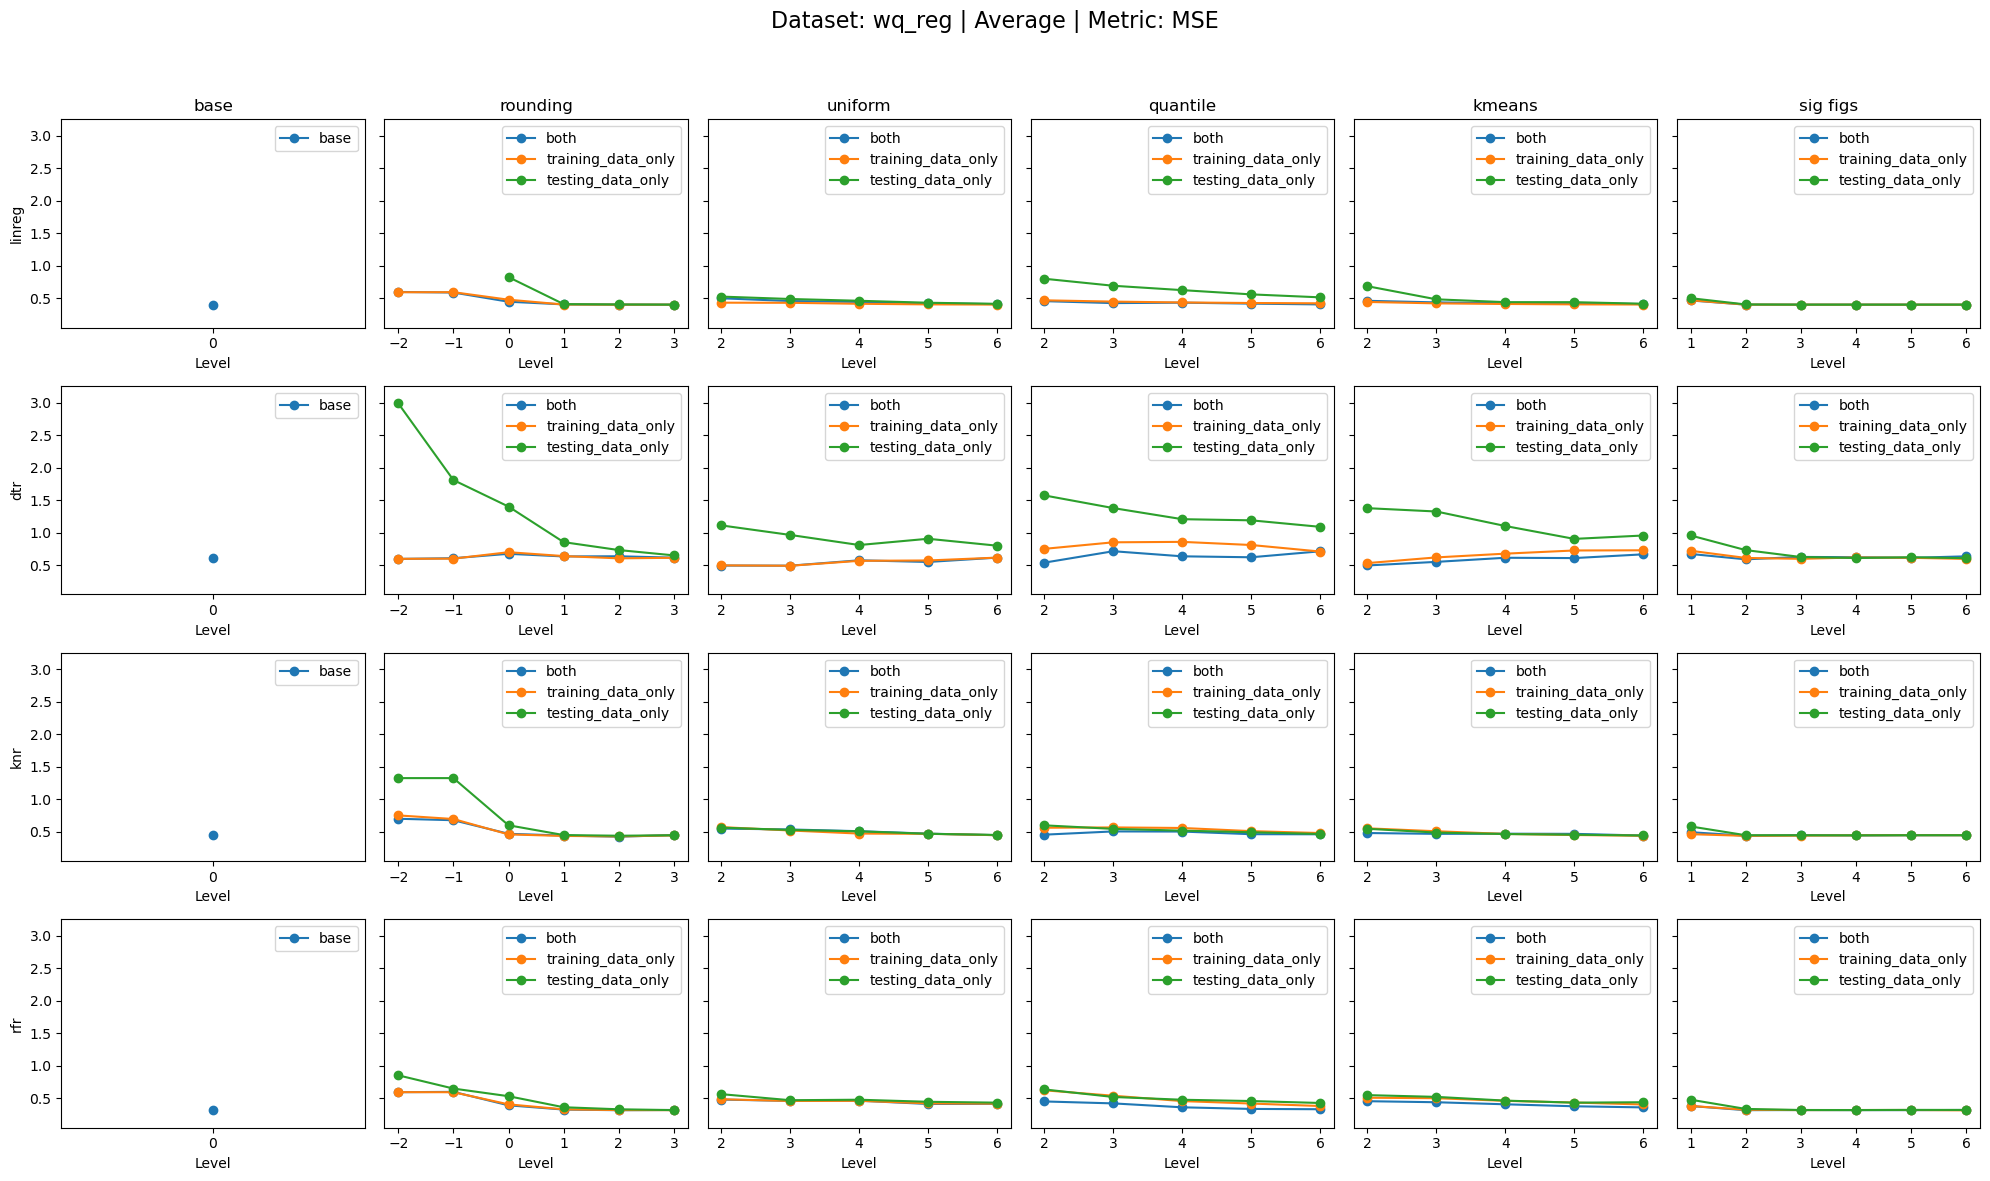

In [63]:
metric = "MSE" 
dfff = new_df  # change to 'accuracy', 'r2', 'mse', or 'mae'
# seed = Average

datasets = dfff['Dataset'].dropna().unique()
models = dfff['Model'].dropna().unique()
methods = dfff['Method'].dropna().unique()

for dataset in datasets:
    

    # filter once for this dataset
    df_d = dfff[
        (dfff['Dataset'] == dataset) &
        (dfff[metric].notna())
    ]

    if df_d.empty:
        continue

    # decide y-limits based on metric
    if metric == 'Accuracy':
        ymin, ymax = 0, 1

    elif metric == 'r2':
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        print(ymin)
        # ymax = data_max + pad

        # optional: cap the top at 1 since R2 usually doesn't exceed 1
        ymax = 1

    elif metric in ['mse', 'mae']:
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min,data_max)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    else:
        # fallback for any other metric
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    fig, axes = plt.subplots(
        len(models),
        len(methods),
        figsize=(20, 12),
        sharey=True
    )

    axes = np.atleast_2d(axes)

    for i, model in enumerate(models):
        for j, method in enumerate(methods):

            ax = axes[i, j]

            subset = df_d[
                (df_d['Model'] == model) &
                (df_d['Method'] == method)
            ]

            if subset.empty:
                ax.set_visible(False)
                continue

            for mode in subset['Mode'].dropna().unique():
                mode_data = subset[subset['Mode'] == mode].sort_values('Level')

                ax.plot(
                    mode_data['Level'],
                    mode_data[metric],
                    marker='o',
                    label=mode
                )

            if i == 0:
                ax.set_title(method)
            if j == 0:
                ax.set_ylabel(model)

            ax.set_xlabel("Level")
            ax.set_xticks(sorted(subset['Level'].dropna().unique()))
            ax.set_ylim(ymin, ymax)

            if metric == 'r2':
                ax.axhline(0, linestyle='--', linewidth=1)

            ax.legend()

    fig.suptitle(
        f"Dataset: {dataset} | Average | Metric: {metric}",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()